# Within-session dynamics of d′

How do visual-cortex representations change trial by trial within one session, and does reward change that? For each of the 26 sessions this notebook computes every neuron's discriminability d′ between the leaf and circle corridors in a window of 20 trial pairs, slides the window one pair at a time, and summarises the population of d′ values in each window.

It is the analysis in `dprime-original.ipynb` rewritten on top of `code/data.py` (data from the Figshare API, stored in DuckDB) and `code/plot.py`. The method is unchanged: Rui's sliding-window d′ with the same trial definition, the same window of 20 pairs, and the same ±0.3 selectivity threshold.

In [1]:
%matplotlib inline
import sys
sys.path.append("../code")

import numpy as np
import pandas as pd

import data
import plot

z = data.Zhong()

from numpy.lib.stride_tricks import sliding_window_view as slide
from scipy.stats import skew

## Trials and per-trial sums

A trial starts when the position jumps back by more than 10 or the wall texture changes. Within a trial only texture-zone frames (position < 40) where the mouse is moving count, and a trial needs at least 3 of them. For every trial I keep each neuron's sum and sum of squares of activity. Any window's mean and standard deviation then follow exactly from these sums.

In [2]:
def trial_sums(session):
    U, V = z.svd(session)
    frames = z.frames(session).iloc[: V.shape[1]]
    wall = frames.wall.fillna("nan")
    start = (frames.position.diff() < -10) | (wall != wall.shift())
    start.iloc[0] = False
    keep = (frames.position < 40) & frames.moving
    rows = []
    for _, trial in frames[keep].groupby(start.cumsum()[keep]):
        if len(trial) >= 3 and trial.role.iloc[0] in ("leaf", "circle"):
            x = U.T @ V[:, trial.frame.to_numpy()]
            rows.append((trial.role.iloc[0], x.sum(1, dtype=float), np.square(x, dtype=float).sum(1), len(trial), trial.speed.sum()))
    return pd.DataFrame(rows, columns=["role", "sum", "squares", "frames", "speed"])

## Sliding-window d′

The i-th leaf trial pairs with the i-th circle trial. Window w covers pairs w to w + 19, and for every neuron

d′ = 2 (μ_leaf − μ_circle) / (σ_leaf + σ_circle)

where μ and σ are the mean and standard deviation of its activity over all frames of the window's leaf or circle trials. Positive d′ means a neuron prefers the leaf corridor.

In [3]:
def moments(trials, n, window):
    total = lambda column: slide(np.stack(trials[column].iloc[:n]), window, axis=0).sum(-1)
    count = slide(trials.frames.iloc[:n].to_numpy(), window).sum(-1)[:, None]
    mean = total("sum") / count
    return mean, np.sqrt(np.clip(total("squares") / count - mean ** 2, 0, None)), count[:, 0]


def dprime(sums, window=20):
    leaf, circle = sums[sums.role == "leaf"], sums[sums.role == "circle"]
    n = min(len(leaf), len(circle))
    (ml, sl, cl), (mc, sc, cc) = moments(leaf, n, window), moments(circle, n, window)
    d = np.nan_to_num(2 * (ml - mc) / (sl + sc + 1e-8), nan=0.0, posinf=0.0, neginf=0.0)
    speed = (slide(leaf.speed.iloc[:n].to_numpy(), window).sum(-1) + slide(circle.speed.iloc[:n].to_numpy(), window).sum(-1)) / (cl + cc)
    return d, speed

## All 26 sessions

For each window I keep the median, standard deviation and skewness of d′ across neurons, the fraction of leaf-selective (d′ ≥ 0.3) and circle-selective (d′ ≤ −0.3) neurons, and the mean running speed. I do this for all neurons and separately for each visual area. The pooled d′ histograms of the first 100 windows feed the distribution plots.

In [4]:
edges = np.linspace(-1.5, 1.5, 61)
stats, histograms = [], []
for session in z.sessions.session:
    d, speed = dprime(trial_sums(session))
    area = z.neurons(session).area.to_numpy()
    for name, selected in [("all", np.ones(len(area), bool)), *[(a, area == a) for a in plot.AREA]]:
        x = d[:, selected]
        stats.append(pd.DataFrame({
            "session": session, "area": name, "window": np.arange(len(x)),
            "median": np.median(x, 1), "sd": x.std(1), "skewness": skew(x, axis=1),
            "leaf_selective": (x >= 0.3).mean(1), "circle_selective": (x <= -0.3).mean(1), "speed": speed,
        }))
    counts = np.stack([np.histogram(row, edges)[0] for row in d[:100]])
    histograms.append(pd.DataFrame({
        "session": session,
        "window": np.repeat(np.arange(len(counts)), len(edges) - 1),
        "bin": np.tile((edges[:-1] + edges[1:]) / 2, len(counts)),
        "count": counts.ravel(),
    }))

stats = pd.concat(stats).merge(z.sessions[["session", "mouse", "condition", "phase"]])
z.save("dprime_windows", stats)
stats.groupby(["condition", "phase"]).agg(mice=("mouse", "nunique"), windows=("window", "size"))

mice  windows
condition    phase                
supervised   after      4     2960
             before     4     1705
unsupervised after      9     7340
             before     9     5980

## How the d′ distribution evolves

These are pooled d′ distributions across mice at five points in each session, with supervised and unsupervised mice overlaid. `plot.animate` writes the same distributions as GIFs, one frame per window, to `figures/` in the data folder.

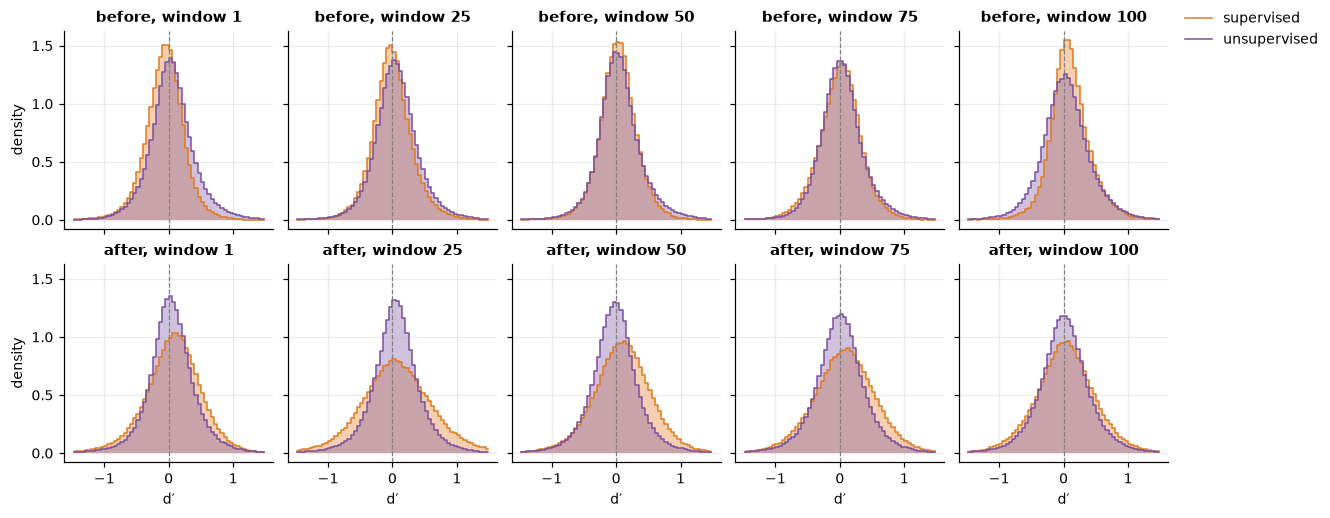

In [5]:
pooled = pd.concat(histograms).merge(z.sessions).groupby(["condition", "phase", "window", "bin"], as_index=False)["count"].sum()
pooled["density"] = pooled["count"] / pooled.groupby(["condition", "phase", "window"])["count"].transform("sum") / np.diff(edges)[0]
plot.distributions(pooled, windows=[0, 24, 49, 74, 99])

In [6]:
figures = z.root / "figures"
figures.mkdir(exist_ok=True)
for phase, part in pooled.groupby("phase"):
    plot.animate(part, figures / f"dprime_{phase}_learning.gif")

## Population statistics across the session

Each line is the mean across mice, and the band is ±1 standard error. Windows are shown while at least two mice in a group still have data, up to window 150.

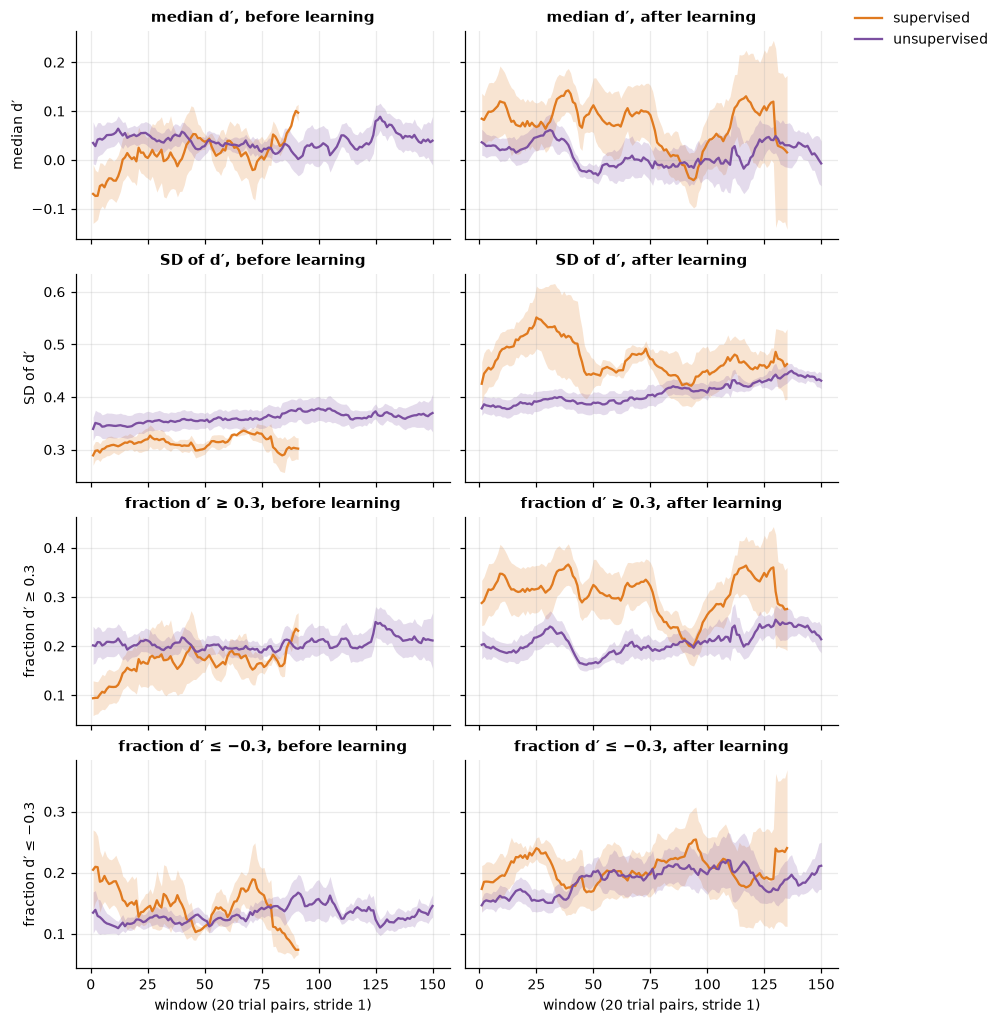

In [7]:
metrics = {"median": "median d′", "sd": "SD of d′", "leaf_selective": "fraction d′ ≥ 0.3", "circle_selective": "fraction d′ ≤ −0.3"}
early = stats[stats.window < 150]
plot.trajectories(early[early.area == "all"], metrics)

## By visual area: V1

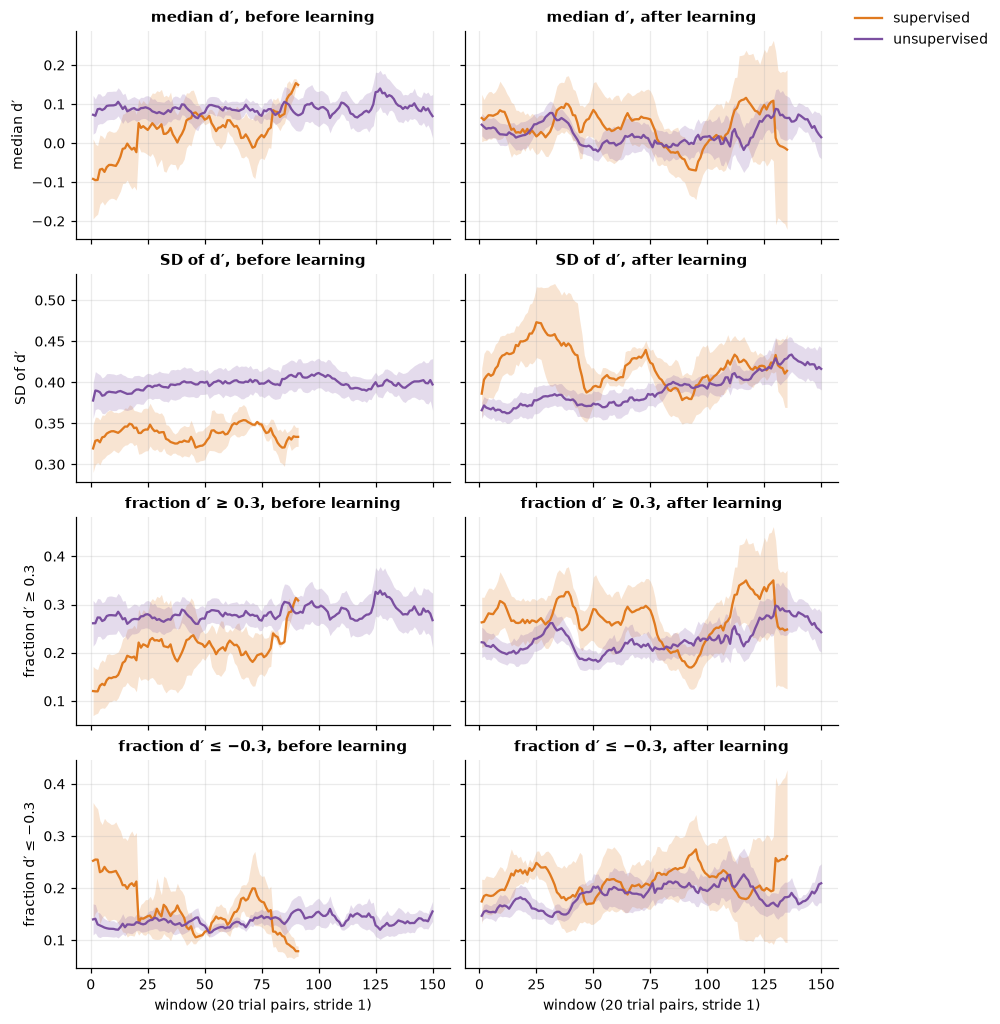

In [8]:
plot.trajectories(early[early.area == "V1"], metrics)

## By visual area: medial higher visual areas (mHV)

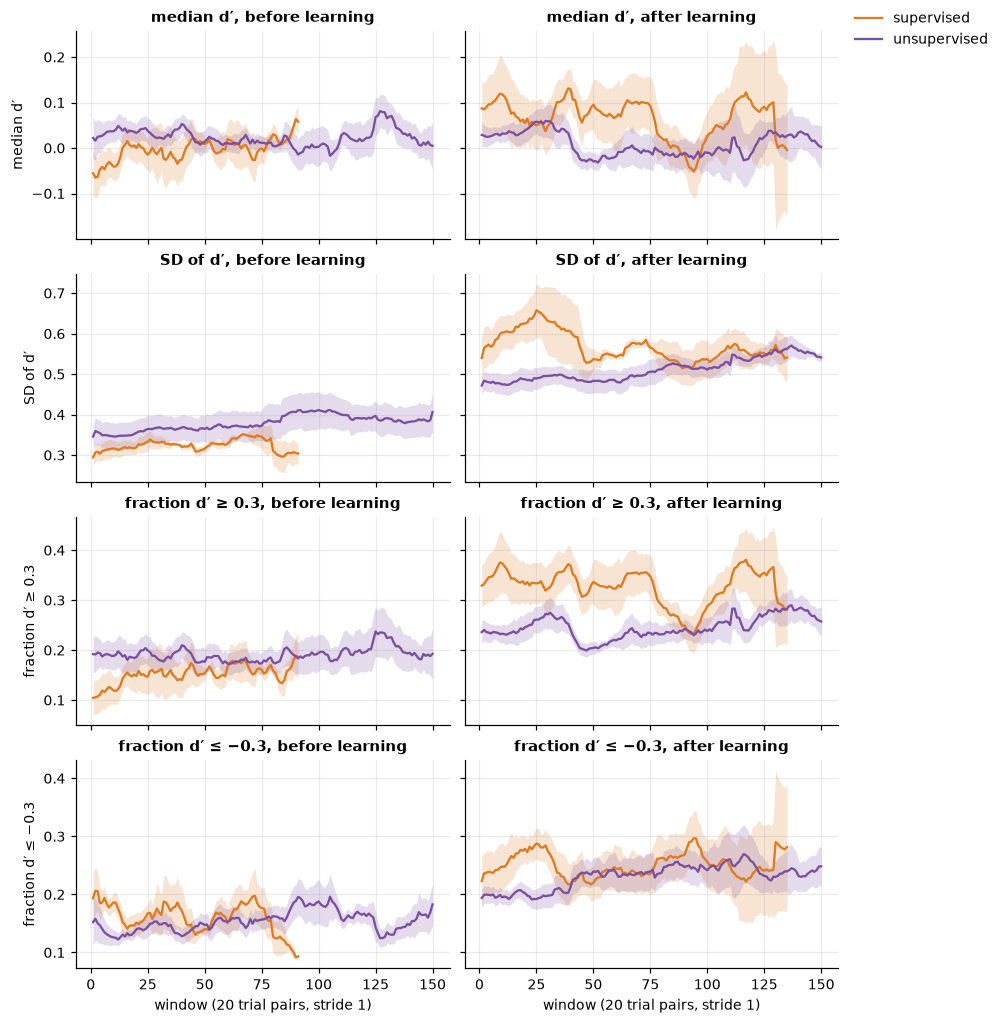

In [9]:
plot.trajectories(early[early.area == "mHV"], metrics)

## Running speed and skewness

Running speed differs between mice and over a session, and it changes visual responses, so it is a confound to keep in view when comparing groups.

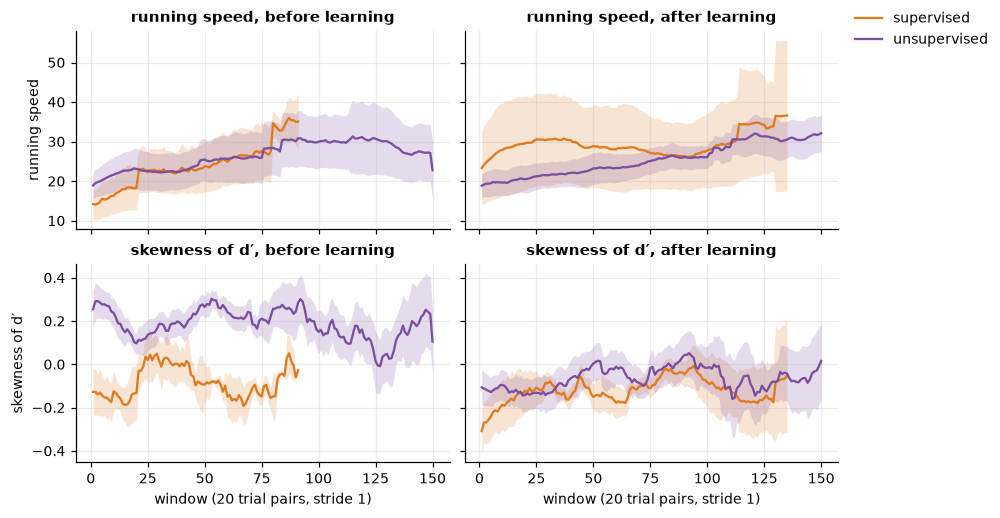

In [10]:
plot.trajectories(early[early.area == "all"], {"speed": "running speed", "skewness": "skewness of d′"})